# Huấn luyện và tối ưu KNN / Decision Tree

**Phần mô hình người3:** Nguyễn Hoàng triển khai KNN/DT gốc; Đặng Quang Tiến (người4) thực hiện phần mở rộng k và regularization DT. Có AI hỗ trợ, không thay trách nhiệm tự xác minh của thành viên.

Notebook đọc kết quả CV/OOF đã lưu trong **report/knn** và **report/dt**, không train, predict, nạp model hoặc chạy official test khi Run All. Điểm test lịch sử không phải điểm test của cấu hình CV mới.

## 1. Dữ liệu và giao thức

Giữ nguyên RGB → ROI → resize32 AREA → /255 → HOG324 của người1/2. StandardScaler fit fold-train; 39.209 ảnh, 1.307 track, frozen3fold seed42. Các kết quả/claims lịch sử không bị thay thế.

[Báo cáo KNN](../report/notes_knn.md) · [Báo cáo DT](../report/notes_dt.md) · [EDA](../report/notes_eda_preprocessing.md)

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT=Path.cwd().resolve()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from scripts.model_artifacts import load_model_runs, resolve_evidence
RUNS={a:ROOT/p for a,p in {'knn': 'report/knn/hog-full-20261115', 'dt': 'report/dt/hog-full-20261115'}.items()}
RUNS,selection,config=load_model_runs(RUNS['knn'],RUNS['dt'])
assert selection['status']=='completed_train_cv'
assert selection['official_test_read'] is False
assert selection['official_test_evaluated'] is False
PREFIX='models_'+RUNS['knn'].name
TABLES=ROOT/'report/tables'
FIGURES=ROOT/'report/figures'
print('Saved train-CV runs:',RUNS)
print('No automatic training or model inference.')

Saved train-CV runs: {'knn': WindowsPath('D:/ML/Traffic_sign_recognition/report/knn/hog-full-20261115'), 'dt': WindowsPath('D:/ML/Traffic_sign_recognition/report/dt/hog-full-20261115')}
No automatic training or model inference.


## 2. Frozen folds và grid

KNN28 cấu hình: k={3,5,7,11,15,21,31}, uniform/distance, Euclidean/Manhattan. DT11 cấu hình: giữ entropy/depth20/split5; thử leaf/class_weight/pruning. Baseline đứng đầu, chọn mean macro-F1, hòa lấy cấu hình đầu.

In [2]:
manifest=pd.read_csv(RUNS['knn']/'fold_manifest.csv')
assert len(manifest)==39209 and manifest.Group.nunique()==1307
assert manifest.groupby('Group').ValidationFold.nunique().eq(1).all()
display(manifest.groupby('ValidationFold').agg(images=('CSVRow','size'),tracks=('Group','nunique')))
display(pd.DataFrame([{'algorithm':a,'candidate_id':c['candidate_id'],**c['params']}
 for a,key in [('knn','knn_candidates'),('dt','dt_candidates')] for c in config[key]]))

,images,tracks
ValidationFold,,
0,13080,436
1,13079,436
2,13050,435


,algorithm,candidate_id,n_neighbors,weights,metric,criterion,max_depth,min_samples_split,min_samples_leaf,class_weight,ccp_alpha
0,knn,knn_baseline,7.0,distance,manhattan,NaN,NaN,NaN,NaN,NaN,NaN
1,knn,knn_k3_uniform_euclidean,3.0,uniform,euclidean,NaN,NaN,NaN,NaN,NaN,NaN
2,knn,knn_k3_uniform_manhattan,3.0,uniform,manhattan,NaN,NaN,NaN,NaN,NaN,NaN
3,knn,knn_k3_distance_euclidean,3.0,distance,euclidean,NaN,NaN,NaN,NaN,NaN,NaN
4,knn,knn_k3_distance_manhattan,3.0,distance,manhattan,NaN,NaN,NaN,NaN,NaN,NaN
5,knn,knn_k5_uniform_euclidean,5.0,uniform,euclidean,NaN,NaN,NaN,NaN,NaN,NaN
6,knn,knn_k5_uniform_manhattan,5.0,uniform,manhattan,NaN,NaN,NaN,NaN,NaN,NaN
7,knn,knn_k5_distance_euclidean,5.0,distance,euclidean,NaN,NaN,NaN,NaN,NaN,NaN
8,knn,knn_k5_distance_manhattan,5.0,distance,manhattan,NaN,NaN,NaN,NaN,NaN,NaN
9,knn,knn_k7_uniform_euclidean,7.0,uniform,euclidean,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Baseline và cấu hình được chọn

So sánh cùng môi trường/folds. Mean fold F1 khác pooled OOF F1. SD3fold không phải CI. Selected OOF dùng chính folds chọn tham số nên có selection bias, không phải nested/unbiased estimate.

,algorithm,role,params,cv_f1_macro_mean,cv_f1_macro_std,pooled_oof_f1_macro,train_images,tracks
0,knn,baseline,"{""metric"": ""manhattan"", ""n_neighbors"": 7, ""wei...",0.809718,0.016981,0.812176,39209,1307
1,knn,selected,"{""metric"": ""manhattan"", ""n_neighbors"": 15, ""we...",0.812096,0.014242,0.813967,39209,1307
2,dt,baseline,"{""ccp_alpha"": 0.0, ""class_weight"": null, ""crit...",0.614898,0.011907,0.616536,39209,1307
3,dt,selected,"{""ccp_alpha"": 0.0005, ""class_weight"": null, ""c...",0.621998,0.013418,0.623811,39209,1307


,algorithm,fold,baseline_f1_macro,selected_f1_macro,delta_f1_macro
0,knn,0,0.833291,0.831790,-0.001500
1,knn,1,0.801902,0.805903,0.004002
2,knn,2,0.793962,0.798596,0.004633
3,dt,0,0.625407,0.631062,0.005655
4,dt,1,0.621037,0.631903,0.010867
5,dt,2,0.598249,0.603028,0.004779


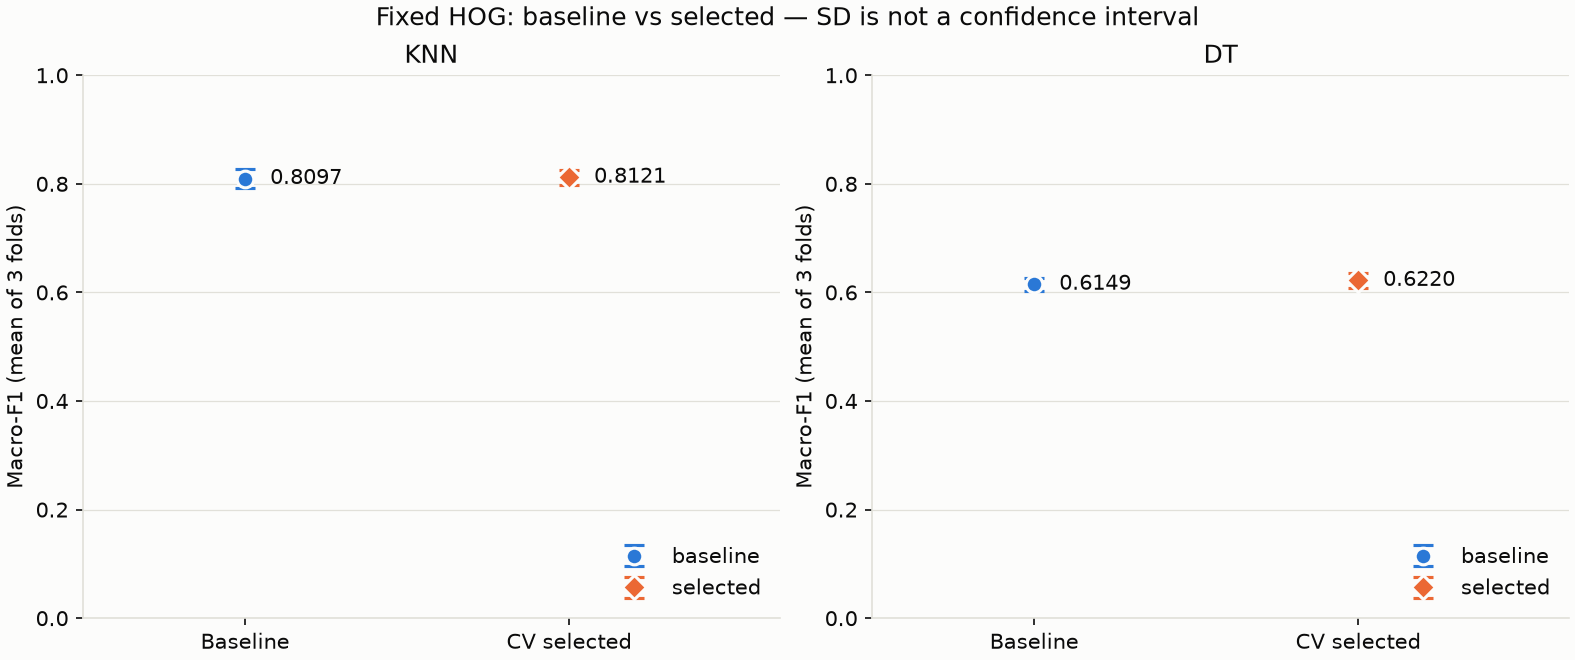

In [3]:
summary=pd.read_csv(TABLES/f'{PREFIX}_summary.csv')
candidates=pd.read_csv(TABLES/f'{PREFIX}_candidates.csv')
display(summary[['algorithm','role','params','cv_f1_macro_mean','cv_f1_macro_std','pooled_oof_f1_macro','train_images','tracks']])
display(pd.read_csv(TABLES/f'{PREFIX}_fold_deltas.csv'))
display(Image(filename=str(FIGURES/f'{PREFIX}_cv_comparison.png')))

## 4. Đường cong k và regularization

KNN tối ưu tái dùng neighbor queries theo metric/fold, batch có giới hạn; hòa ở biên k dùng sklearn fallback. DT giữ grid có mục tiêu, không exhaustive interactions.

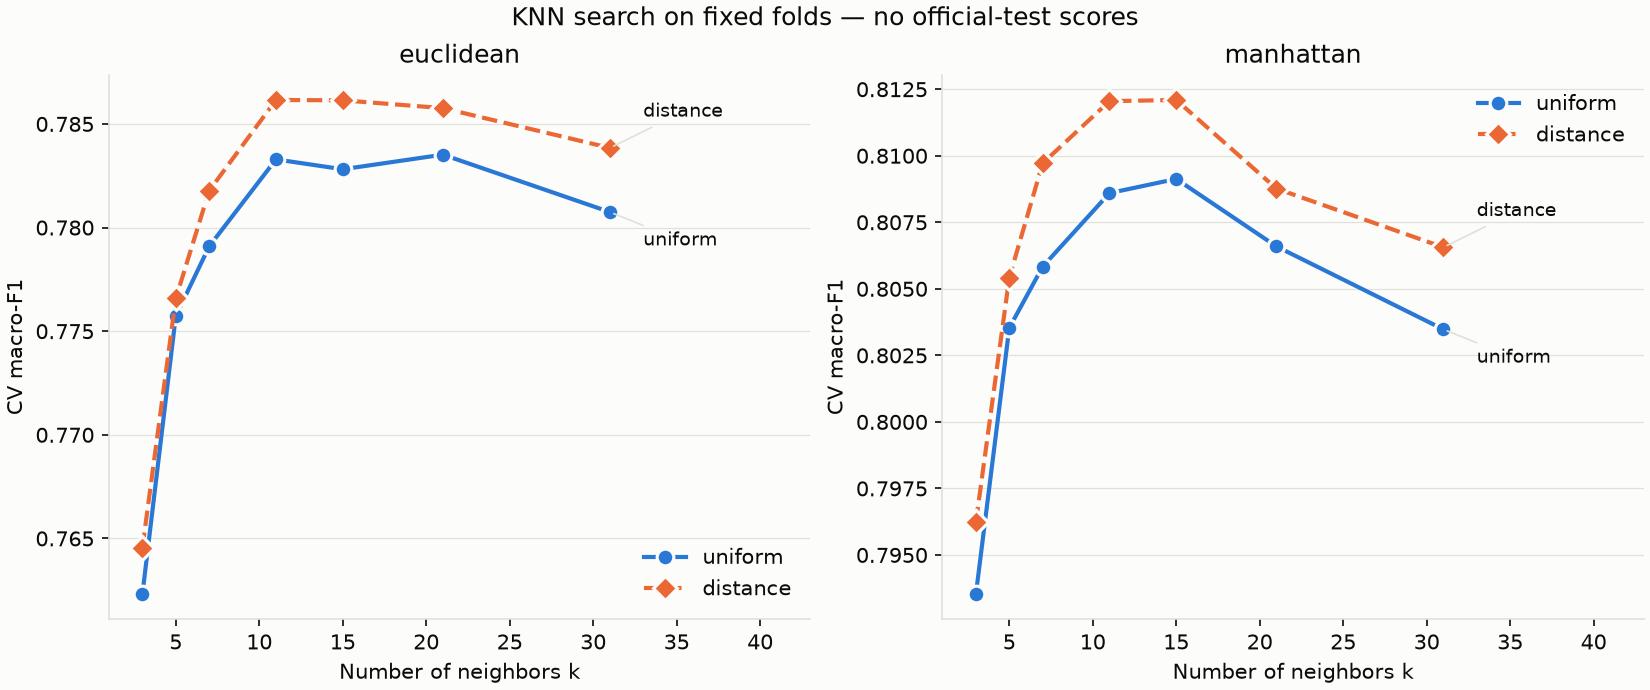

KNN


,candidate_id,params,mean_f1_macro,mean_accuracy,mean_precision_macro,mean_recall_macro,std_f1_macro,cv_seconds_sum,timing_scope,algorithm,mean_train_f1_macro
19,knn_k15_distance_manhattan,"{""metric"": ""manhattan"", ""n_neighbors"": 15, ""we...",0.812096,0.827031,0.849469,0.792949,0.014242,0.362786,candidate_only_excludes_shared_scaler_and_neig...,knn,NaN
15,knn_k11_distance_manhattan,"{""metric"": ""manhattan"", ""n_neighbors"": 11, ""we...",0.812052,0.825600,0.846993,0.793726,0.015870,0.410175,candidate_only_excludes_shared_scaler_and_neig...,knn,NaN
0,knn_baseline,"{""metric"": ""manhattan"", ""n_neighbors"": 7, ""wei...",0.809718,0.822310,0.841146,0.793689,0.016981,0.386591,candidate_only_excludes_shared_scaler_and_neig...,knn,NaN
17,knn_k15_uniform_manhattan,"{""metric"": ""manhattan"", ""n_neighbors"": 15, ""we...",0.809129,0.824990,0.849172,0.788912,0.014069,0.336265,candidate_only_excludes_shared_scaler_and_neig...,knn,NaN
23,knn_k21_distance_manhattan,"{""metric"": ""manhattan"", ""n_neighbors"": 21, ""we...",0.808766,0.827156,0.849622,0.788559,0.015376,0.406067,candidate_only_excludes_shared_scaler_and_neig...,knn,NaN
13,knn_k11_uniform_manhattan,"{""metric"": ""manhattan"", ""n_neighbors"": 11, ""we...",0.808597,0.823738,0.846195,0.789163,0.015523,0.303560,candidate_only_excludes_shared_scaler_and_neig...,knn,NaN
21,knn_k21_uniform_manhattan,"{""metric"": ""manhattan"", ""n_neighbors"": 21, ""we...",0.806593,0.825856,0.849585,0.785447,0.014417,0.449283,candidate_only_excludes_shared_scaler_and_neig...,knn,NaN
27,knn_k31_distance_manhattan,"{""metric"": ""manhattan"", ""n_neighbors"": 31, ""we...",0.806561,0.827131,0.853781,0.784588,0.013698,0.582614,candidate_only_excludes_shared_scaler_and_neig...,knn,NaN


DT


,candidate_id,params,mean_f1_macro,mean_accuracy,mean_precision_macro,mean_recall_macro,std_f1_macro,cv_seconds_sum,timing_scope,algorithm,mean_train_f1_macro
37,dt_alpha_5e-4,"{""ccp_alpha"": 0.0005, ""class_weight"": null, ""c...",0.621998,0.666930,0.644055,0.611930,0.013418,320.417203,fit_and_train_valid_predict_excludes_shared_sc...,dt,0.870078
32,dt_leaf5_none,"{""ccp_alpha"": 0.0, ""class_weight"": null, ""crit...",0.619172,0.662849,0.639281,0.609592,0.014591,292.759245,fit_and_train_valid_predict_excludes_shared_sc...,dt,0.893095
31,dt_leaf2_balanced,"{""ccp_alpha"": 0.0, ""class_weight"": ""balanced"",...",0.617673,0.650083,0.622955,0.623657,0.002675,306.247916,fit_and_train_valid_predict_excludes_shared_sc...,dt,0.952867
30,dt_leaf2_none,"{""ccp_alpha"": 0.0, ""class_weight"": null, ""crit...",0.617341,0.659816,0.640009,0.607762,0.009405,337.323064,fit_and_train_valid_predict_excludes_shared_sc...,dt,0.945887
29,dt_leaf1_balanced,"{""ccp_alpha"": 0.0, ""class_weight"": ""balanced"",...",0.617153,0.649904,0.626922,0.618982,0.003422,316.844960,fit_and_train_valid_predict_excludes_shared_sc...,dt,0.964257
28,dt_baseline,"{""ccp_alpha"": 0.0, ""class_weight"": null, ""crit...",0.614898,0.658769,0.635185,0.606562,0.011907,307.717904,fit_and_train_valid_predict_excludes_shared_sc...,dt,0.958216
36,dt_alpha_1e-4,"{""ccp_alpha"": 0.0001, ""class_weight"": null, ""c...",0.614898,0.658769,0.635185,0.606562,0.011907,305.588369,fit_and_train_valid_predict_excludes_shared_sc...,dt,0.958216
34,dt_leaf10_none,"{""ccp_alpha"": 0.0, ""class_weight"": null, ""crit...",0.614008,0.664078,0.633602,0.606539,0.008043,280.980365,fit_and_train_valid_predict_excludes_shared_sc...,dt,0.831071


In [4]:
display(Image(filename=str(FIGURES/f'{PREFIX}_knn_k_curve.png')))
for algorithm in ['knn','dt']:
 print(algorithm.upper())
 display(candidates.loc[candidates.algorithm.eq(algorithm)].sort_values('mean_f1_macro',ascending=False,kind='stable').head(8))

## 5. H2 — lớp và số track

Support/track/F1 chỉ mô tả. Lớp ít ảnh không tất yếu yếu; frame cùng track không độc lập. Không chọn mô hình bằng bảng lỗi official test.

In [5]:
classes=pd.read_csv(TABLES/f'{PREFIX}_oof_classes.csv')
for algorithm in ['knn','dt']:
 part=classes.loc[classes.algorithm.eq(algorithm)&classes.role.eq('selected')]
 print(algorithm.upper(),'weakest classes')
 display(part.sort_values('f1').head(10))

KNN weakest classes


,algorithm,role,class_id,train_images,train_tracks,oof_support,precision,recall,f1
70,knn,selected,27,240,8,240,0.568862,0.395833,0.466830
73,knn,selected,30,450,15,450,0.589235,0.462222,0.518057
48,knn,selected,5,1860,62,1860,0.496092,0.580108,0.534820
72,knn,selected,29,270,9,270,0.626168,0.496296,0.553719
51,knn,selected,8,1410,47,1410,0.595105,0.603546,0.599296
44,knn,selected,1,2220,74,2220,0.720067,0.585135,0.645626
63,knn,selected,20,360,12,360,0.753676,0.569444,0.648734
66,knn,selected,23,510,17,510,0.676113,0.654902,0.665339
45,knn,selected,2,2250,75,2250,0.621652,0.742667,0.676792
65,knn,selected,22,390,13,390,0.763158,0.669231,0.713115


DT weakest classes


,algorithm,role,class_id,train_images,train_tracks,oof_support,precision,recall,f1
159,dt,selected,30,450,15,450,0.227941,0.206667,0.216783
158,dt,selected,29,270,9,270,0.266436,0.285185,0.275492
156,dt,selected,27,240,8,240,0.289593,0.266667,0.277657
134,dt,selected,5,1860,62,1860,0.332801,0.336022,0.334403
168,dt,selected,39,300,10,300,0.556250,0.296667,0.386957
157,dt,selected,28,540,18,540,0.387978,0.394444,0.391185
137,dt,selected,8,1410,47,1410,0.392883,0.391489,0.392185
130,dt,selected,1,2220,74,2220,0.402463,0.456306,0.427697
169,dt,selected,40,360,12,360,0.467742,0.402778,0.432836
155,dt,selected,26,600,20,600,0.444444,0.426667,0.435374


## 6. H3 — kích thước, chất lượng và cặp nhầm

Ngưỡng kích thước32 từ EDA. Brightness/contrast đo trên ROI đã resize32; quartile fit fold-train, khác brightness toàn ảnh ở EDA. Chưa kiểm soát class/track nên không suy nhân quả, chưa đo blur.

,algorithm,role,dimension,group,n,errors,error_rate
0,knn,baseline,raw_min_dimension,ge32,32704,5169,0.158054
1,knn,baseline,raw_min_dimension,lt32,6505,1798,0.276403
2,knn,baseline,roi_min_dimension,ge32,20712,2695,0.130118
3,knn,baseline,roi_min_dimension,lt32,18497,4272,0.230956
4,knn,baseline,sign_family,other,26429,3142,0.118885
5,knn,baseline,sign_family,speed_limit,12780,3825,0.299296
6,knn,baseline,roi32_brightness,high_train_quartile,9798,1624,0.165748
7,knn,baseline,roi32_brightness,low_train_quartile,9766,1791,0.183391
8,knn,baseline,roi32_brightness,middle,19645,3552,0.180809
9,knn,baseline,roi32_contrast,high_train_quartile,9812,1608,0.163881


,algorithm,role,fold,measurement,q25_fold_train,q75_fold_train
0,knn,baseline,0,roi32_brightness,0.182149,0.449648
1,knn,baseline,1,roi32_brightness,0.182093,0.451011
2,knn,baseline,2,roi32_brightness,0.178211,0.447174
3,knn,baseline,0,roi32_contrast,0.074929,0.216287
4,knn,baseline,1,roi32_contrast,0.075602,0.218696
5,knn,baseline,2,roi32_contrast,0.075063,0.217165


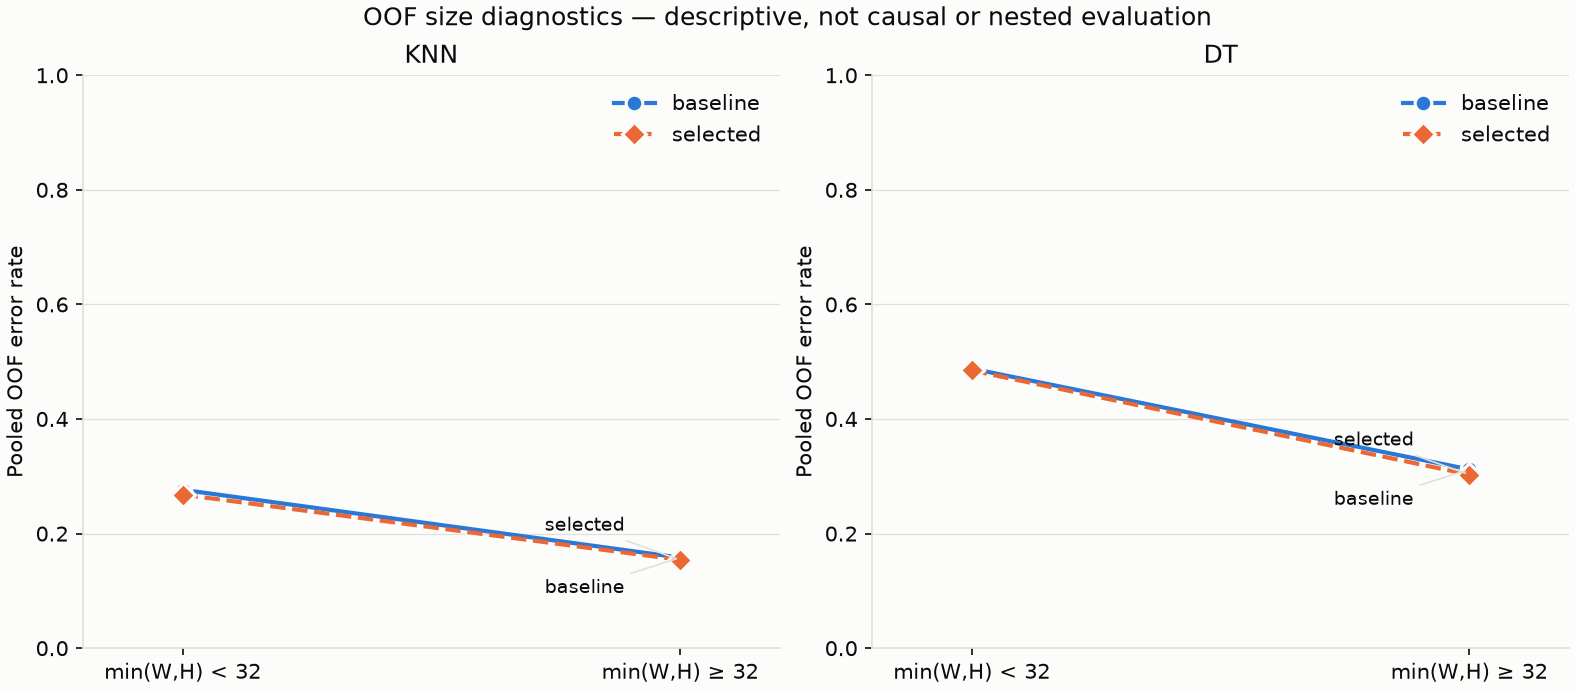

,algorithm,role,true_class,predicted_class,count,within_speed_classes
2,knn,selected,1,2,397,True
11,knn,selected,1,5,338,True
14,knn,selected,5,2,278,True
18,knn,selected,2,5,239,True
22,knn,selected,8,7,184,True
23,knn,selected,5,1,182,True
26,knn,selected,8,5,178,True
28,knn,selected,7,8,174,True
39,knn,selected,3,5,143,True
40,knn,selected,2,1,143,True


,algorithm,role,true_class,predicted_class,count,within_speed_classes
0,dt,selected,5,1,440,True
7,dt,selected,1,2,367,True
8,dt,selected,1,5,352,True
9,dt,selected,2,1,343,True
12,dt,selected,5,2,320,True
19,dt,selected,2,5,216,True
24,dt,selected,7,8,180,True
31,dt,selected,8,7,170,True
33,dt,selected,25,11,165,False
34,dt,selected,8,5,160,True


In [6]:
groups=pd.read_csv(TABLES/f'{PREFIX}_oof_groups.csv')
pairs=pd.read_csv(TABLES/f'{PREFIX}_oof_error_pairs.csv')
display(groups)
display(pd.read_csv(TABLES/f'{PREFIX}_quality_thresholds.csv').head(6))
display(Image(filename=str(FIGURES/f'{PREFIX}_oof_size_errors.png')))
for algorithm in ['knn','dt']:
 display(pairs.loc[pairs.algorithm.eq(algorithm)&pairs.role.eq('selected')].head(12))

## 7. Timing và provenance

Candidate KNN timings không gồm shared scaler/query; không cộng chúng như end-to-end. CV wall time và refit được ghi riêng. Không so tốc độ giữa môi trường khác nhau. Hashes gốc giữ nguyên; bản đồ chuyển đường dẫn chỉ tìm đúng bytes đã ghi nhận.

In [7]:
display(pd.DataFrame([{'algorithm':item['algorithm'],'candidates':item['candidate_count'],'cv_seconds':item['cv_wall_seconds'],'refit_seconds':item['refit_seconds'],'model_MiB':item['model_bytes']/2**20} for item in selection['algorithms']]))
provenance=json.loads((ROOT/'logs/knn'/RUNS['knn'].name/'export_provenance.json').read_text(encoding='utf-8'))
for relative,expected in provenance['sources_sha256'].items():
 resolve_evidence(relative,expected,project_root=ROOT)
print('Recorded-source hashes verified; no models deserialized.')

,algorithm,candidates,cv_seconds,refit_seconds,model_MiB
0,knn,28,280.835387,0.241761,42.777009
1,dt,11,3410.951293,149.248237,0.113168


Recorded-source hashes verified; no models deserialized.


## 8. Tái lập có chủ ý

Run-id phải mới; các lệnh train không tự chạy khi Run All.

```powershell
& data/.venv-model3/Scripts/python.exe scripts/train_models.py preflight --dataset-dir data --run-id hog-preflight-new
& data/.venv-model3/Scripts/python.exe scripts/train_models.py tune --dataset-dir data --run-id hog-full-new
& data/.venv-model3/Scripts/python.exe scripts/summarize_models.py --knn-run report/knn/hog-full-new --dt-run report/dt/hog-full-new
```

Pins môi trường: scripts/requirements_models.txt. Chưa official-test score cho models mới; test đã được EDA thăm dò. Chưa repeated/nested CV, chưa CI/significance. Bảng/ảnh nằm report/tables và report/figures, có bản dark.